In [128]:
from utils import readin_raw, find_fds_for_rhs, fuzzy_filter,turnListToString, writeBackTrainingData, convertToDataFrame

In [129]:
import pandas as pd

In [130]:
data = pd.read_csv('../dataset.csv')

In [131]:
data

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False
...,...,...,...,...,...,...,...
563,546,points,firstseason,women_basketball.csv,False,True,False
564,547,points,lastseason,women_basketball.csv,False,True,False
565,548,birthDate,collegeOther,women_basketball.csv,False,True,False
566,549,birthDate,deathDate,women_basketball.csv,False,True,False


In [132]:
from sentence_transformers import SentenceTransformer
from sklearn.metrics.pairwise import cosine_similarity

sentenceTransformer = SentenceTransformer("all-MiniLM-L6-v2")


In [133]:
texts = ["cat", "dog", "machine leaadwdlnawdrninawdasdg"]
embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)

sim = cosine_similarity(embeddings)

print(sim)

[[1.         0.6606377  0.16261399]
 [0.6606377  1.         0.2098045 ]
 [0.16261399 0.2098045  1.        ]]


In [134]:
gen_data = data[data['is_genuine']]
nongen_data = data[data['is_genuine'] == False]

In [135]:
def build_cosine_sim(row):
    lhs = row['lhs']
    rhs = row['rhs']
    texts = [lhs, rhs]
    embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
    sim = cosine_similarity(embeddings)
    return sim[0][1]

In [136]:
gen_similarites_unclean = gen_data.apply(build_cosine_sim, axis=1)

In [137]:
ungen_similarites_clean = nongen_data.apply(build_cosine_sim, axis=1)

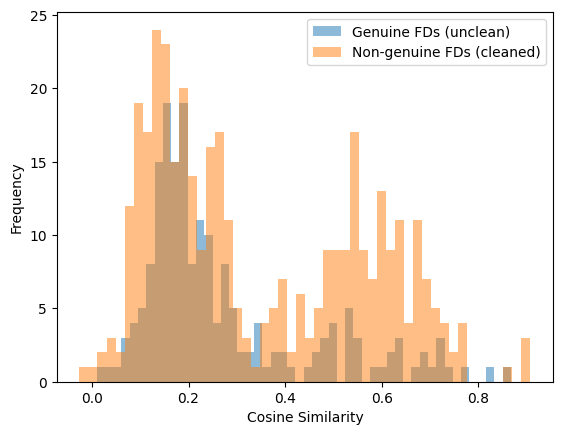

In [138]:
import matplotlib.pyplot as plt
plt.hist(gen_similarites_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_similarites_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [139]:
type(gen_similarites_unclean)

pandas.core.series.Series

In [140]:
texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.0000001 , 0.17218286],
       [0.17218286, 1.        ]], dtype=float32)

In [141]:
import Levenshtein
print(Levenshtein.distance(texts[0], texts[1]))

12


In [142]:
def build_levenshtein(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    min_distance = float('inf')
    for lhs_elem in lhs:
        distance = Levenshtein.distance(lhs_elem, rhs)
        if distance < min_distance:
            min_distance = distance
    return min_distance

In [143]:
gen_leven_unclean = gen_data.apply(build_levenshtein, axis=1)
ungen_leven_clean = nongen_data.apply(build_levenshtein, axis=1)

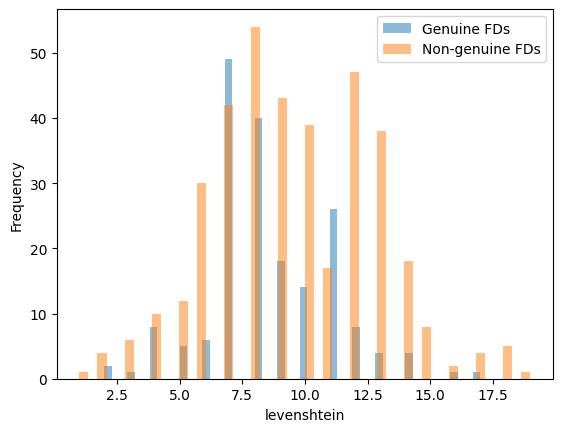

In [144]:
import matplotlib.pyplot as plt
plt.hist(gen_leven_unclean, bins=50, alpha=0.5, label='Genuine FDs')
plt.hist(ungen_leven_clean, bins=50, alpha=0.5, label='Non-genuine FDs')
plt.xlabel('levenshtein')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [145]:
def longest_common_substring(a: str, b: str) -> str:
    if not a or not b:
        return ""

    dp = [0] * (len(b) + 1)
    best_len = 0
    best_end = 0 

    for i in range(1, len(a) + 1):
        prev_diag = 0
        for j in range(1, len(b) + 1):
            tmp = dp[j]
            if a[i - 1] == b[j - 1]:
                dp[j] = prev_diag + 1
                if dp[j] > best_len:
                    best_len = dp[j]
                    best_end = i
            else:
                dp[j] = 0
            prev_diag = tmp

    return a[best_end - best_len:best_end]



In [146]:
def build_lcs(row):
    lhs = [x.strip() for x in row['lhs'].split(',')]
    rhs = row['rhs']
    max_distance = 0
    for lhs_elem in lhs:
        distance = len(longest_common_substring(lhs_elem, rhs))
        if distance > max_distance:
            max_distance = distance
    return max_distance

In [147]:
gen_lcs_unclean = gen_data.apply(build_lcs, axis=1)
ungen_lcs_clean = nongen_data.apply(build_lcs, axis=1)

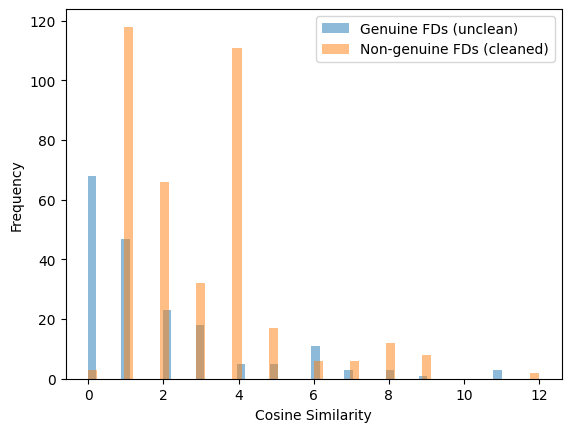

In [148]:
import matplotlib.pyplot as plt
plt.hist(gen_lcs_unclean, bins=50, alpha=0.5, label='Genuine FDs (unclean)')
plt.hist(ungen_lcs_clean, bins=50, alpha=0.5, label='Non-genuine FDs (cleaned)')
plt.xlabel('Cosine Similarity')
plt.ylabel('Frequency')
plt.legend()
plt.show()

In [149]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

df = pd.DataFrame()
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

X = df[["cosine_sim", "lcs", "leven"]]
y = df["is_genuine"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [150]:
df

,cosine_sim,lcs,leven,is_genuine
0,0.681850,6,2,True
1,0.640750,6,9,True
2,0.620726,6,2,True
3,0.503650,6,9,True
4,0.191531,3,14,True
...,...,...,...,...
563,0.236703,2,9,False
564,0.204836,2,9,False
565,0.144032,2,10,False
566,0.598772,6,3,False


In [151]:
clf = DecisionTreeClassifier(
    max_depth=5,        # prevents overfitting
    min_samples_leaf=5, # smoother splits
    random_state=42
)

clf.fit(X_train, y_train)


DecisionTreeClassifier(max_depth=5, min_samples_leaf=5, random_state=42)

In [152]:
y_pred = clf.predict(X_test)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.7017543859649122
              precision    recall  f1-score   support

       False       0.72      0.91      0.80        76
        True       0.61      0.29      0.39        38

    accuracy                           0.70       114
   macro avg       0.66      0.60      0.60       114
weighted avg       0.68      0.70      0.67       114



In [153]:
import pandas as pd

importance = pd.Series(
    clf.feature_importances_,
    index=X.columns
).sort_values(ascending=False)

print(importance)


lcs           0.745485
leven         0.135289
cosine_sim    0.119226
dtype: float64


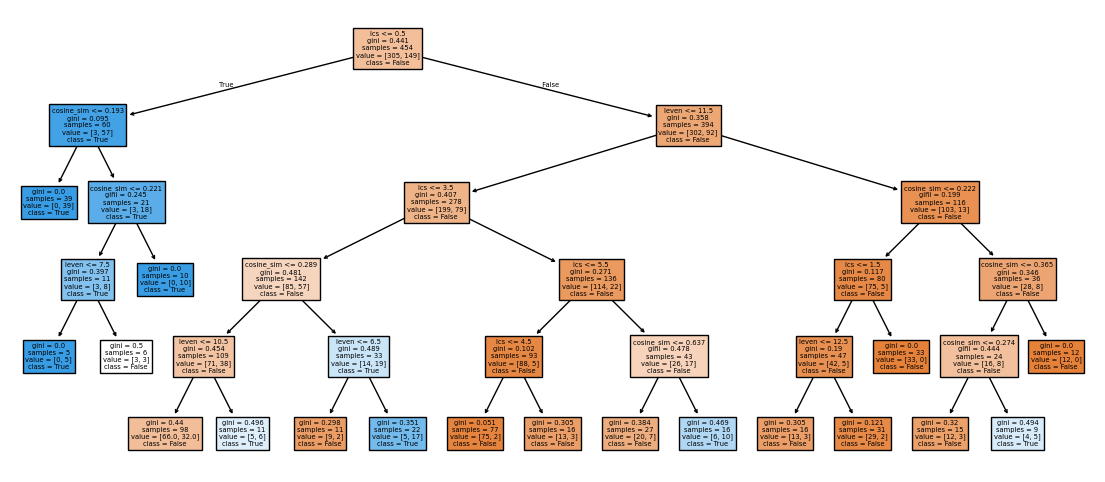

In [154]:
from sklearn.tree import plot_tree
import matplotlib.pyplot as plt

plt.figure(figsize=(14, 6))
plot_tree(
    clf,
    feature_names=X.columns,
    class_names=["False", "True"],
    filled=True
)
plt.show()


In [155]:
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import classification_report, accuracy_score

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)


In [156]:
clf = LogisticRegression(
    solver="lbfgs",
    max_iter=1000,
    class_weight="balanced",  # helpful if classes are imbalanced
    random_state=42
)

clf.fit(X_train_scaled, y_train)


LogisticRegression(class_weight='balanced', max_iter=1000, random_state=42)

In [157]:
y_pred = clf.predict(X_test_scaled)

print("Accuracy:", accuracy_score(y_test, y_pred))
print(classification_report(y_test, y_pred))


Accuracy: 0.6842105263157895
              precision    recall  f1-score   support

       False       0.78      0.74      0.76        76
        True       0.52      0.58      0.55        38

    accuracy                           0.68       114
   macro avg       0.65      0.66      0.65       114
weighted avg       0.69      0.68      0.69       114



In [158]:
y_pred

array([False, False,  True, False, False, False, False,  True,  True,
       False,  True, False, False,  True, False, False,  True,  True,
        True, False, False,  True,  True, False, False, False, False,
        True, False,  True, False, False, False, False, False,  True,
       False, False, False, False,  True, False, False,  True, False,
        True,  True,  True, False, False, False, False,  True,  True,
        True,  True, False, False, False,  True, False, False,  True,
       False, False,  True, False, False, False, False,  True, False,
       False, False, False,  True,  True,  True, False,  True, False,
       False,  True,  True,  True, False,  True,  True, False,  True,
       False, False,  True, False, False, False, False, False, False,
        True, False, False,  True,  True,  True,  True, False, False,
       False, False, False, False, False, False])

In [159]:
raw_texts = ['DepDelay', 'DepartureDelayGroups']
embeddings = sentenceTransformer.encode(raw_texts, normalize_embeddings=True)
cosine_similarity(embeddings)

array([[1.0000001 , 0.17218286],
       [0.17218286, 1.        ]], dtype=float32)

In [160]:
Levenshtein.distance(raw_texts[0], raw_texts[1])

12

In [161]:
longest_common_substring(raw_texts[0], raw_texts[1])

'Delay'

In [162]:
import re

CAMEL_CASE_PATTERN = re.compile(
    r'''
    [A-Z]+(?=[A-Z][a-z]) |   # Acronyms followed by Capitalized words
    [A-Z]?[a-z]+ |           # Capitalized or lowercase words
    [A-Z]+ |                 # All-caps words
    \d+                      # Numbers
    ''',
    re.VERBOSE
)

def camel_case_tokenize(text: str) -> list[str]:
    return CAMEL_CASE_PATTERN.findall(text)


In [163]:
texts = camel_case_tokenize(raw_texts[0]) + camel_case_tokenize(raw_texts[1])
print(texts)

['Dep', 'Delay', 'Departure', 'Delay', 'Groups']


In [164]:
embeddings = sentenceTransformer.encode(texts, normalize_embeddings=True)
sim = cosine_similarity(embeddings)

In [165]:
sim

array([[1.0000002 , 0.23588921, 0.2667036 , 0.23588921, 0.2343167 ],
       [0.23588921, 0.9999997 , 0.27791515, 0.9999997 , 0.29369226],
       [0.2667036 , 0.27791515, 1.0000001 , 0.27791515, 0.26653332],
       [0.23588921, 0.9999997 , 0.27791515, 0.9999997 , 0.29369226],
       [0.2343167 , 0.29369226, 0.26653332, 0.29369226, 1.0000001 ]],
      dtype=float32)

In [166]:
import numpy as np
levenshteins = np.array([], dtype=np.int16)
for t1 in texts:
    row = []
    for t2 in texts:
        row.append(Levenshtein)

## Building Features

### considering data type

In [167]:
# todo function: databasename + attributename -> SQL Type
#basketball team: "bioID","firstName","middleName","lastName","nameGiven","fullGivenName","marriedName","nameNick","pos","firstseason","lastseason","height","weight","college","collegeOther","birthDate","birthCity","birthState","birthCountry","highSchool","hsCity","hsState","hsCountry","deathDate","year","stint","tmID","lgID","GP","GS","minutes","points","oRebounds","dRebounds","rebounds","assists","steals","blocks","turnovers","PF","fgAttempted","fgMade","ftAttempted","ftMade","threeAttempted","threeMade","dq","PostGP","PostGS","PostMinutes","PostPoints","PostoRebounds","PostdRebounds","PostRebounds","PostAssists","PostSteals","PostBlocks","PostTurnovers","PostPF","PostfgAttempted","PostfgMade","PostftAttempted","PostftMade","PostthreeAttempted","PostthreeMade","PostDQ"
basektball_datatypes = {'bioID': 'varchar', 'firstName': 'varchar', 'middleName': 'varchar', 'lastName': 'varchar', 'nameGiven': 'varchar', 'fullGivenName': 'varchar', 'marriedName': 'varchar', 'nameNick': 'varchar', 'pos': 'varchar', 'firstseason':'int', 'lastseason':'int', 'height': 'float', 'weight':'int', 'college':'varchar', 'collegeOther':'varchar', 'birthDate':'date', 'birthCity':'varchar', 'birthState':'varchar', 'birthCountry':'varchar', 'highSchool':'varchar', 'hsCity':'varchar', 'hsState':'varchar', 'hsCountry':'varchar', 'deathDate':'date', 'year':'int', 'stint':'int', 'tmID':'varchar', 'lgID':'varchar', 'GP':'int', 'GS':'int', 'minutes':'int', 'points':'int', 'oRebounds':'int', 'dRebounds':'int', 'rebounds':'int', 'assists':'int', 'steals':'int', 'blocks':'int', 'turnovers':'int', 'PF':'int', 'fgAttempted':'int', 'fgMade':'int', 'ftAttempted':'int', 'ftMade':'int', 'threeAttempted':'int', 'threeMade':'int', 'dq':'int', 'PostGP':'int', 'PostGS':'int', 'PostMinutes':'int', 'PostPoints':'int', 'PostoRebounds':'int', 'PostdRebounds':'int', 'PostRebounds':'int', 'PostAssists':'int', 'PostSteals':'int', 'PostBlocks':'int', 'PostTurnovers':'int', 'PostPF':'int', 'PostfgAttempted':'int', 'PostfgMade':'int', 'PostftAttempted':'int', 'PostftMade':'int', 'PostthreeAttempted':'int', 'PostthreeMade':'int', 'PostDQ':'int'}
airline_datatypes ={ 'Year': 'int', 'Quarter':'int', 'Month':'int', 'DayofMonth':'int', 'DayOfWeek':'int', 'FlightDate':'date', 'UniqueCarrier':'varchar', 'AirlineID':'int', 'Carrier':'char', 'TailNum':'varchar', 'FlightNum':'int', 'OriginAirportID':'int', 'OriginAirportSeqID':'int', 'OriginCityMarketID':'int', 'Origin': 'char', 'OriginCityName': 'varchar', 'OriginState': 'char', 'OriginStateFips': 'int', 'OriginStateName': 'varchar', 'OriginWac': 'int', 'DestAirportID': 'int', 'DestAirportSeqID':'int', 'DestCityMarketID':'int', 'Dest':'char', 'DestCityName':'varchar', 'DestState':'char', 'DestStateFips':'int', 'DestStateName':'varchar', 'DestWac':'int', 'CRSDepTime':'int', 'DepTime':'int', 'DepDelay':'decimal', 'DepDelayMinutes':'float', 'DepDel15':'int', 'DepartureDelayGroups':'int', 'DepTimeBlk':'char', 'TaxiOut':'float', 'TaxiIn':'float', 'CRSArrTime':'int', 'ArrTime':'int', 'ArrDelay': 'decimal', 'ArrDelayMinutes': 'float', 'ArrDel15': 'int', 'ArrivalDelayGroups': 'ArrivalDelayGroups', 'ArrTimeBlk': 'char', 'Cancelled': 'int', 'CancellationCode': 'char', 'Diverted': 'int', 'CRSElapsedTime': 'float',  'ActualElapsedTime': 'float', 'AirTime': 'float', 'Flights': 'float', 'Distance':'float', 'DistanceGroup':'int', 'CarrierDelay': 'decimal', 'WeatherDelay':'decimal', 'NASDelay':'decimal', 'SecurityDelay':'decimal', 'LateAircraftDelay':'decimal', 'FirstDepTime':'decimal', 'TotalAddGTime':'decimal', 'LongestAddGTime':'decimal'}
mondial_datatypes = {"country_code": 'varchar',  "country_name":'varchar',  "country_capital_name":'varchar',  "country_capital_province":'varchar',  "country_area":'int',  "country_population":'int',  "city_position":'varchar',  "city_name":'varchar',  "city_country_code":'varchar',  "city_province":'varchar',  "city_population":'int',  "city_latitude":'double',  "city_longitude":'double',  "city_elevation":'int',  "airport_iata_code":'varchar',  "airport_name":'varchar',  "airport_country_code":'varchar',  "airport_city_name":'varchar',  "airport_province":'varchar',  "airport_island":'varchar',  "airport_latitude":'float',  "airport_longitude":'float',  "airport_elevation":'int',  "airport_gmt_offset":'int',  "language_name":'varchar',  "language_percentage":'double'  }
northwind_datatypes = {"OrderID":'int', "CustomerID":'varchar', "EmployeeID":'int', "ProductID":'int', "ord_OrderDate":'timestamp', "ord_RequiredDate":'timestamp', "ord_ShippedDate":'timestamp', "ord_ShipVia":'int', "ord_Freight":'double', "ord_ShipName":'varchar', "ord_ShipAddress":'varchar', "ord_ShipCity":'varchar', "ord_ShipRegion":'varchar', "ord_ShipPostalCode":'varchar', "ord_ShipCountry":'varchar', "cust_CompanyName":'varchar', "cust_ContactName":'varchar', "cust_ContactTitle":'varchar', "cust_Address":'varchar', "cust_City":'varchar', "cust_Region":'varchar', "cust_PostalCode":'varchar', "cust_Country":'varchar', "cust_Phone":'varchar', "cust_Fax":'varchar', "emp_LastName":'varchar', "emp_FirstName":'varchar', "emp_Title":'varchar', "emp_TitleOfCourtesy":'varchar', "emp_BirthDate":'timestamp', "emp_HireDate":'timestamp', "emp_Address":'varchar', "emp_City":'varchar', "emp_Region":'varchar', "emp_PostalCode":'varchar', "emp_Country":'varchar', "emp_HomePhone":'varchar', "emp_Extension":'int', "emp_ReportsTo":'int', "od_UnitPrice":'double', "od_Quantity": 'int', "od_Discount":'double', "prd_ProductName":'varchar', "prd_SupplierID":'int', "prd_CategoryID":'int', "prd_QuantityPerUnit":'varchar', "prd_UnitPrice":'double', "prd_UnitsInStock":'int', "prd_UnitsOnOrder":'int', "prd_ReorderLevel":'int', "prd_Discontinued":'bool',}
financial_datatypes = {"account_id": 'int', "account_date": 'date', "disp_id":'int', "disp_type":'varchar', "client_id":'int', "gender": 'varchar', "birth_date":'date', "district_id":'int', "A2":'varchar', "A3":'varchar', "A4":'int', "A5":'int', "A6":'int', "A7":'int', "A8":'int', "A9":'int', "A10":'decimal', "A11":'int', "A12":'decimal', "A13":'decimal', "A14":'int', "A15":'int', "A16":'int', "loan_id":'int', "loan_date":'date', "loan_amount":'int', "duration":'int', "payments":'decimal', "status": 'varchar', "order_id":'int', "bank_to":'varchar', "account_to":'int', "order_amount":'decimal', "k_symbol":'varchar'}

In [168]:
data['tablename'].unique()

array(['croppedairline.csv', 'mondialjoin.csv', 'northwind.csv',
       'financial.csv', 'women_basketball.csv'], dtype=object)

In [169]:
def datatype_for_row(lhs, rhs, dataset_name):
    datatypes = {}
    if dataset_name == 'croppedairline.csv':
        datatypes = airline_datatypes
    elif dataset_name == 'women_basketball.csv':
        datatypes = basektball_datatypes
    elif dataset_name == 'mondialjoin.csv':
        datatypes = mondial_datatypes
    elif dataset_name == 'northwind.csv':
        datatypes = northwind_datatypes
    elif dataset_name == 'financial.csv':
        datatypes = financial_datatypes
    else:
        return 'unknown', 'unknown'
    
    lhs_types = []
    for attr in lhs.split(','):
        attr = attr.strip()
        if attr in datatypes:
            lhs_types.append(datatypes[attr])
        else:
            lhs_types.append('unknown')
    
    rhs_type = datatypes.get(rhs, 'unknown')
    
    return ','.join(lhs_types), rhs_type

In [170]:
data_ft = data.copy() 
data_ft[['lhs_datatypes', 'rhs_datatype']] = data.apply(lambda row: datatype_for_row(row['lhs'], row['rhs'], row['tablename']), axis=1, result_type="expand")

In [171]:
data_ft.head()

,id,lhs,rhs,tablename,is_approx,null_eq_nul,is_genuine,lhs_datatypes,rhs_datatype
0,0,DepTime,ArrDel15,croppedairline.csv,True,True,False,int,int
1,1,ArrTime,ArrDel15,croppedairline.csv,True,True,False,int,int
2,2,TailNum,ArrDel15,croppedairline.csv,True,True,False,varchar,int
3,3,ActualElapsedTime,ArrDel15,croppedairline.csv,True,True,False,float,int
4,4,AirTime,ArrDel15,croppedairline.csv,True,True,False,float,int


In [172]:
result = data_ft.groupby(['lhs_datatypes', 'rhs_datatype','is_genuine']).size().unstack(fill_value=0)

In [173]:
result.sort_values(by=False,axis=0, ascending=False)

is_genuine                            False  True 
lhs_datatypes           rhs_datatype              
varchar                 varchar          86     31
int                     int              41     66
varchar                 int              35      4
float                   int              20      2
int                     varchar          15     43
...                                     ...    ...
                        double            0      1
char                    int               0      2
double,double           varchar           0      1
char                    varchar           0      2
varchar,varchar,varchar varchar           0      1

[83 rows x 2 columns]

In [174]:
def compute_posterior(true_fds, false_fds):
    prior_alpha = 0.5
    prior_beta = 0.5
    alpha_post = prior_alpha + true_fds
    beta_post = prior_beta + false_fds
    mean = alpha_post / (alpha_post + beta_post)
    var = (alpha_post * beta_post) / ((alpha_post + beta_post)**2 * (alpha_post + beta_post + 1))
    return mean,var

In [175]:
datatypes_dist = pd.DataFrame()
datatypes_dist[['mean', 'var' ]] = result.apply(lambda row: compute_posterior(row[True], row[False]), axis=1,result_type="expand")

In [176]:
datatypes_dist.sort_values(by='var', ascending=False)

,,mean,var
lhs_datatypes,rhs_datatype,,
ArrivalDelayGroups,int,0.250000,0.062500
"int,varchar,varchar",double,0.250000,0.062500
"double,double",varchar,0.750000,0.062500
float,float,0.250000,0.062500
"float,float",int,0.250000,0.062500
...,...,...,...
int,varchar,0.737288,0.003228
varchar,int,0.112500,0.002435
int,int,0.615741,0.002171


(array([ 4.,  3.,  2.,  2.,  0.,  0.,  1.,  2.,  0.,  0.,  3.,  0.,  1.,
         0.,  0.,  0., 11.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,
         0., 26.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  1.,  0.,
         0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0.,  0., 27.]),
 array([0.00164443, 0.00286154, 0.00407865, 0.00529577, 0.00651288,
        0.00772999, 0.0089471 , 0.01016421, 0.01138132, 0.01259843,
        0.01381554, 0.01503266, 0.01624977, 0.01746688, 0.01868399,
        0.0199011 , 0.02111821, 0.02233532, 0.02355244, 0.02476955,
        0.02598666, 0.02720377, 0.02842088, 0.02963799, 0.0308551 ,
        0.03207222, 0.03328933, 0.03450644, 0.03572355, 0.03694066,
        0.03815777, 0.03937488, 0.040592  , 0.04180911, 0.04302622,
        0.04424333, 0.04546044, 0.04667755, 0.04789466, 0.04911177,
        0.05032889, 0.051546  , 0.05276311, 0.05398022, 0.05519733,
        0.05641444, 0.05763155, 0.05884867, 0.06006578, 0.06128289,
        0.0625    ]),
 <BarContainer

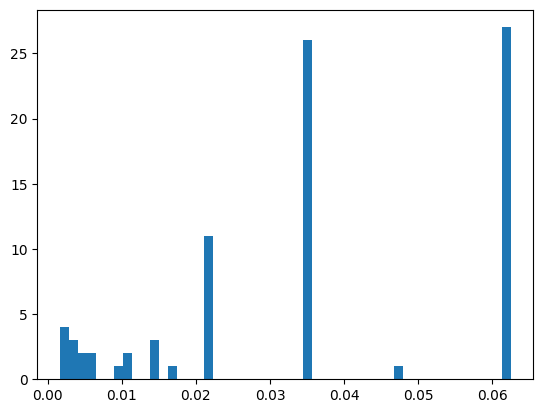

In [177]:
plt.hist(datatypes_dist['var'], bins=50, alpha=1, label='Variance of FD correctness by datatype pair')

In [178]:
datatypes_dist.sort_values(by='mean', ascending=False)

mean       var
lhs_datatypes  rhs_datatype                    
int            timestamp     0.900000  0.015000
char           varchar       0.833333  0.034722
               int           0.833333  0.034722
int            decimal       0.763158  0.009037
               bool          0.750000  0.062500
...                               ...       ...
int,decimal    varchar       0.062500  0.006510
double,varchar varchar       0.055556  0.005247
float          varchar       0.055556  0.005247
varchar        timestamp     0.045455  0.003616
timestamp      varchar       0.033333  0.002014

[83 rows x 2 columns]

In [179]:
def wrapper_lhs(entry):
    lhs = entry['lhs']
    rhs = entry['rhs']
    dataset_name = entry['tablename']
    lhs_types, _ = datatype_for_row(lhs, rhs, dataset_name)
    return lhs_types

def wrapper_rhs(entry):
    lhs = entry['lhs']
    rhs = entry['rhs']
    dataset_name = entry['tablename']
    _, rhs_type = datatype_for_row(lhs, rhs, dataset_name)
    return rhs_type

In [180]:

gen_lhs_type = gen_data.apply(wrapper_lhs, axis=1)
gen_rhs_type = gen_data.apply(wrapper_rhs, axis=1)

ungen_lhs_type = nongen_data.apply(wrapper_lhs, axis=1)
ungen_rhs_type = nongen_data.apply(wrapper_rhs, axis=1)

In [181]:
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.metrics import classification_report, accuracy_score

df = pd.DataFrame()
df['cosine_sim'] = pd.concat([gen_similarites_unclean, ungen_similarites_clean], ignore_index=True)
df['lcs'] = pd.concat([gen_lcs_unclean, ungen_lcs_clean], ignore_index=True)
df['leven'] = pd.concat([gen_leven_unclean, ungen_leven_clean], ignore_index=True)
df['data_type_lhs'] = pd.concat([gen_lhs_type, ungen_lhs_type], ignore_index=True)
df['data_type_rhs'] = pd.concat([gen_rhs_type, ungen_rhs_type], ignore_index=True)
df['is_genuine'] = [True] * len(gen_similarites_unclean) + [False] * len(ungen_similarites_clean)

X = df[["cosine_sim", "lcs", "leven","data_type_lhs", "data_type_rhs"]]
y = df["is_genuine"]

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y  # important for classification
)


In [ ]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

num_cols = ["cosine_sim", "lcs", "leven"]
cat_cols = ["data_type_lhs", "data_type_rhs"]

preprocess = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

model = Pipeline(steps=[
    ("preprocess", preprocess),
    ("clf", LogisticRegression(max_iter=1000))
])

model.fit(X_train, y_train)
pred = model.predict(X_test)

print(classification_report(y_test, pred))
ratio = len(pred[pred]) /len(pred)
print(f"pruning ratio in test data: {ratio}")


              precision    recall  f1-score   support

       False       0.89      0.86      0.87        76
        True       0.73      0.79      0.76        38

    accuracy                           0.83       114
   macro avg       0.81      0.82      0.82       114
weighted avg       0.84      0.83      0.83       114

pruning ratio in test data: 0.35964912280701755


In [ ]:
proba = model.predict_proba(X_test)[:, 1]  # probability of True

threshold = 0.3
pred_adjusted_old = (proba >= threshold)
print(classification_report(y_test, pred_adjusted_old))

              precision    recall  f1-score   support

       False       0.94      0.82      0.87        76
        True       0.71      0.89      0.79        38

    accuracy                           0.84       114
   macro avg       0.82      0.86      0.83       114
weighted avg       0.86      0.84      0.85       114



In [184]:
ratio = len(pred[pred]) /len(pred)
print(f"pruning ratio in test data: {ratio}")

pruning ratio in test data: 0.42105263157894735


In [185]:
# seperator signs upperCase, hyphen, underscore
# has id, key, name, identifier
from itertools import product
import re

# global list for key indicators
keyAlike = ['id', 'key', 'name', 'identifier']
def upper_case_key(entry):
    lhs = entry['lhs']
    def split_by_uppercase(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        parts = re.split(r"(?<=[a-z0-9])(?=[A-Z])|(?<=[A-Z])(?=[A-Z][a-z])", s)
        return [p for p in parts if p]
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    split_has_key = False
    for attribute in attributes:
        up_split = split_by_uppercase( attribute )
        split_has_key = split_has_key or any(p[0].lower() == p[1].lower() for p in product(up_split, keyAlike))
    return split_has_key

def hyphen_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    def split_by_hyphen(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        return [p for p in s.split("-") if p]
    
    split_has_hyphen = False
    for attribute in attributes:
        hy_split = split_by_hyphen( attribute )
        split_has_hyphen = split_has_hyphen or any(p[0].lower() == p[1].lower() for p in product(hy_split, keyAlike))
    return split_has_hyphen

def underscore_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    def split_by_underscore(s: str) -> list[str]:
        s = s.strip()
        if not s:
            return []
        return [p for p in s.split("_") if p]
    
    split_has_underscore = False
    for attribute in attributes:
        un_split = split_by_underscore( attribute )
        split_has_underscore = split_has_underscore or any(p[0].lower() == p[1].lower() for p in product(un_split, keyAlike))
    return split_has_underscore

def contains_key(entry):
    lhs = entry['lhs']
    attributes = [a.strip() for a in lhs.split(',') if a.strip()]
    
    contains_any = any( key.lower() in attribute.lower() for attribute,key in product(attributes, keyAlike) )
    return contains_any


In [218]:
class FeatureBuilder: 
    def __init__(self):
        self.feature_functions = {}

    def add_feature(self, name, func):
        self.feature_functions[name] = func

    def build_dataset(self, data, exclude_table=None):
        df = pd.DataFrame()

        for name, func in self.feature_functions.items():
            df[name] = data.apply(func, axis=1)

        X = df[self.feature_functions.keys()]
        y = data["is_genuine"]
        X_train, X_test, y_train, y_test = train_test_split(
            X,
            y,
            test_size=0.2,
            random_state=42,
            stratify=y  # important for classification
        )
        return X_train, X_test, y_train, y_test
    def clear_features(self):
        self.feature_functions = {}

In [219]:
bob = FeatureBuilder()

In [220]:
bob.clear_features()
bob.add_feature('cosine_sim', build_cosine_sim)
bob.add_feature('lcs', build_lcs)
bob.add_feature('leven', build_levenshtein)
bob.add_feature('data_type_lhs', wrapper_lhs)
bob.add_feature('data_type_rhs', wrapper_rhs)
bob.add_feature('key_case', upper_case_key)
bob.add_feature('underscore_key', underscore_key)
bob.add_feature('contains_key', contains_key)
bob.add_feature('hyphen_key', hyphen_key)

In [221]:
X_train, X_test, y_train, y_test = bob.build_dataset(data)

In [222]:

from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.metrics import classification_report
from sklearn.linear_model import LogisticRegression

num_cols_without = ["cosine_sim", "lcs", "leven" ]
num_cols_with = ["cosine_sim", "lcs", "leven", "key_case","underscore_key","contains_key" ]
cat_cols = ["data_type_lhs", "data_type_rhs"]

preprocess_without = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols_without),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

preprocess_with = ColumnTransformer(
    transformers=[
        ("num", "passthrough", num_cols_with),
        ("cat", OneHotEncoder(handle_unknown="ignore"), cat_cols),
    ]
)

model_with= Pipeline(steps=[
    ("preprocess", preprocess_with),
    ("clf", LogisticRegression(max_iter=1000))
])

model_without= Pipeline(steps=[
    ("preprocess", preprocess_without),
    ("clf", LogisticRegression(max_iter=1000))
])

model_with.fit(X_train, y_train)
model_without.fit(X_train, y_train)
pedict_with = model_with.predict(X_test)
pedict_without = model_without.predict(X_test)


### Comparison keysubstring

In [223]:

print(classification_report(y_test, pedict_without))
ratio = len(pedict_without[pedict_without]) /len(pedict_without)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.89      0.86      0.87        76
        True       0.73      0.79      0.76        38

    accuracy                           0.83       114
   macro avg       0.81      0.82      0.82       114
weighted avg       0.84      0.83      0.83       114

pruning ratio in test data: 0.35964912280701755


In [224]:

print(classification_report(y_test, pedict_with))
ratio = len(pedict_with[pedict_with]) /len(pedict_with)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.89      0.89      0.89        76
        True       0.79      0.79      0.79        38

    accuracy                           0.86       114
   macro avg       0.84      0.84      0.84       114
weighted avg       0.86      0.86      0.86       114

pruning ratio in test data: 0.3333333333333333


### adjusted threshold

In [230]:
proba = model_with.predict_proba(X_test)[:, 1]  # probability of True

threshold = 0.3
pred_adjusted = (proba >= threshold)
print(classification_report(y_test, pred_adjusted))
ratio = len(pred_adjusted[pred_adjusted]) /len(pred_adjusted)
print(f"pruning ratio in test data: {ratio}")

              precision    recall  f1-score   support

       False       0.95      0.75      0.84        76
        True       0.65      0.92      0.76        38

    accuracy                           0.81       114
   macro avg       0.80      0.84      0.80       114
weighted avg       0.85      0.81      0.81       114

pruning ratio in test data: 0.47368421052631576
